# Project 8: Heart Disease Prediction
A hospital wants a first-pass screening model that flags patients at higher risk of heart disease based on clinical measurements 
such as blood pressure, cholesterol, and heart rate. 

## Import Libraries

In [57]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, roc_auc_score

## Download and load dataset into pandas dataframe

In [2]:
path = "archive (6)/heart.csv"
df = pd.read_csv(path)
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1


## 3. Inspect columns: age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak, slope, ca, thal, target. 
### 3.1 Checking column names

In [4]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

This tells us which columns are present in the dataframe. 
### 3.2 Checking data types and non-null counts

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


This helps identify:
- Whether numerical columns have appropriate data types.
- Whether categorical columns are stored as integers.
- Whether there are missing values.

### 3.3 Checking statistical summaries

In [6]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


## 4. Data Cleaning
### 4.1 Check for and handle any placeholder missing values in 'ca' and 'thal'.

In [7]:
df.isnull()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1021,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1022,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1023,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [8]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [13]:
print("Null values in ca and thal: ")
print("ca: ", df['ca'].isnull().sum())
print("thal: ", df['thal'].isnull().sum())

Null values in ca and thal: 
ca:  0
thal:  0


Hence, there are no null values.
### 4.2 Confirm categorical-coded columns (cp, restecg, slope, thal) use consistent integer categories.

In [15]:
categorical_cols = ['cp', 'restecg', 'slope', 'thal']
print(df[categorical_cols].dtypes)

cp         int64
restecg    int64
slope      int64
thal       int64
dtype: object


So, all columns contain int64 data type.

### 4.3 Verify no duplicate patient records exist. 

In [20]:
print("Number of duplicate records: ", df.duplicated().sum())
print("All rows involved in duplication:",
      df.duplicated(keep=False).sum())

Number of duplicate records:  723
All rows involved in duplication: 1025


In [21]:
duplicates = df[df.duplicated(keep='first')]
print(duplicates)

      age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
15     34    0   1       118   210    0        1      192      0      0.7   
31     50    0   1       120   244    0        1      162      0      1.1   
43     46    1   0       120   249    0        0      144      0      0.8   
55     55    1   0       140   217    0        1      111      1      5.6   
61     66    0   2       146   278    0        0      152      0      0.0   
...   ...  ...  ..       ...   ...  ...      ...      ...    ...      ...   
1020   59    1   1       140   221    0        1      164      1      0.0   
1021   60    1   0       125   258    0        0      141      1      2.8   
1022   47    1   0       110   275    0        0      118      1      1.0   
1023   50    0   0       110   254    0        0      159      0      0.0   
1024   54    1   0       120   188    0        1      113      0      1.4   

      slope  ca  thal  target  
15        2   0     2       1  
31        2

In [22]:
df = df.drop_duplicates()

print("Dataset shape after cleaning:", df.shape)

print("Remaining duplicates:", df.duplicated().sum())

Dataset shape after cleaning: (302, 14)
Remaining duplicates: 0


### 4.4 Check that numeric ranges (age, trestbps, chol) are clinically plausible.

In [23]:
columns = ['age', 'trestbps', 'chol']

print(df[columns].describe())

             age    trestbps        chol
count  302.00000  302.000000  302.000000
mean    54.42053  131.602649  246.500000
std      9.04797   17.563394   51.753489
min     29.00000   94.000000  126.000000
25%     48.00000  120.000000  211.000000
50%     55.50000  130.000000  240.500000
75%     61.00000  140.000000  274.750000
max     77.00000  200.000000  564.000000


All are in plausible min-max ranges.

## 5. EDA
### 5.1 Compare disease rate by sex and chest pain type (cp) using bar plots. 

In [25]:
sex_rate = df.groupby('sex')['target'].mean() * 100
print(sex_rate)

sex
0    75.000000
1    44.660194
Name: target, dtype: float64


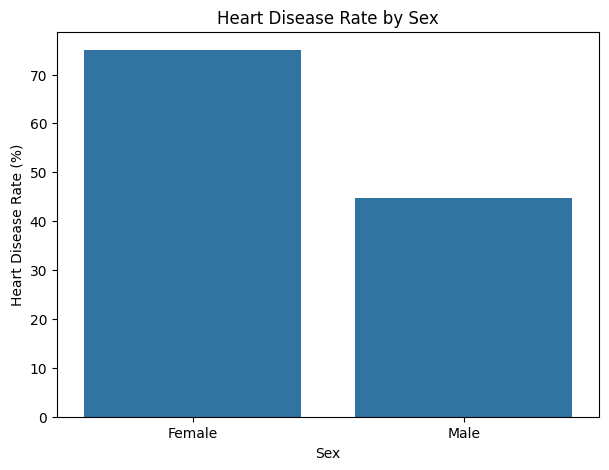

In [28]:
plt.figure(figsize=(7, 5))

sns.barplot(x=sex_rate.index, y=sex_rate.values)

plt.xticks([0, 1], ['Female', 'Male'])
plt.xlabel('Sex')
plt.ylabel('Heart Disease Rate (%)')
plt.title('Heart Disease Rate by Sex')

plt.show()

In [29]:
cp_rate = df.groupby('cp')['target'].mean() * 100

print(cp_rate)

cp
0    27.272727
1    82.000000
2    79.069767
3    69.565217
Name: target, dtype: float64


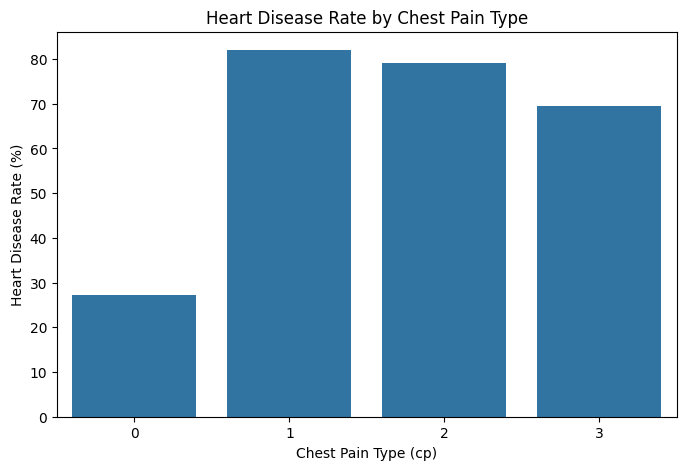

In [30]:
plt.figure(figsize=(8, 5))

sns.barplot(x=cp_rate.index, y=cp_rate.values)

plt.xlabel('Chest Pain Type (cp)')
plt.ylabel('Heart Disease Rate (%)')
plt.title('Heart Disease Rate by Chest Pain Type')

plt.show()

### 5.2 Plot thalach (max heart rate) distribution split by target.

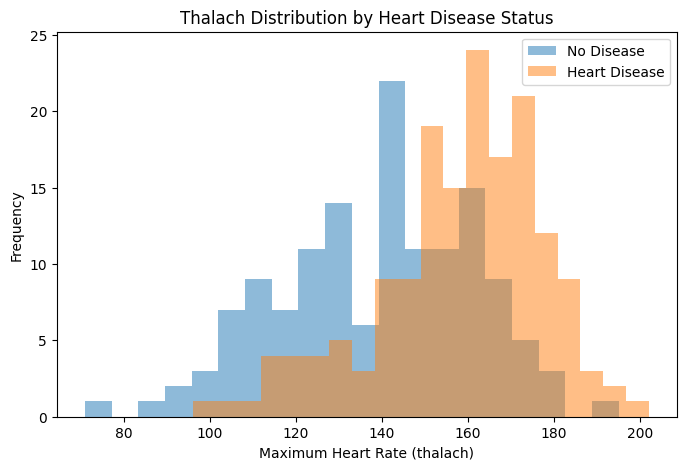

In [32]:
plt.figure(figsize=(8, 5))

plt.hist(df[df['target'] == 0]['thalach'], bins=20, alpha=0.5, label='No Disease')
plt.hist(df[df['target'] == 1]['thalach'], bins=20, alpha=0.5, label='Heart Disease')

plt.xlabel('Maximum Heart Rate (thalach)')
plt.ylabel('Frequency')
plt.title('Thalach Distribution by Heart Disease Status')

plt.legend()
plt.show()

### 5.3 Build a correlation heatmap of all numeric features against target. 

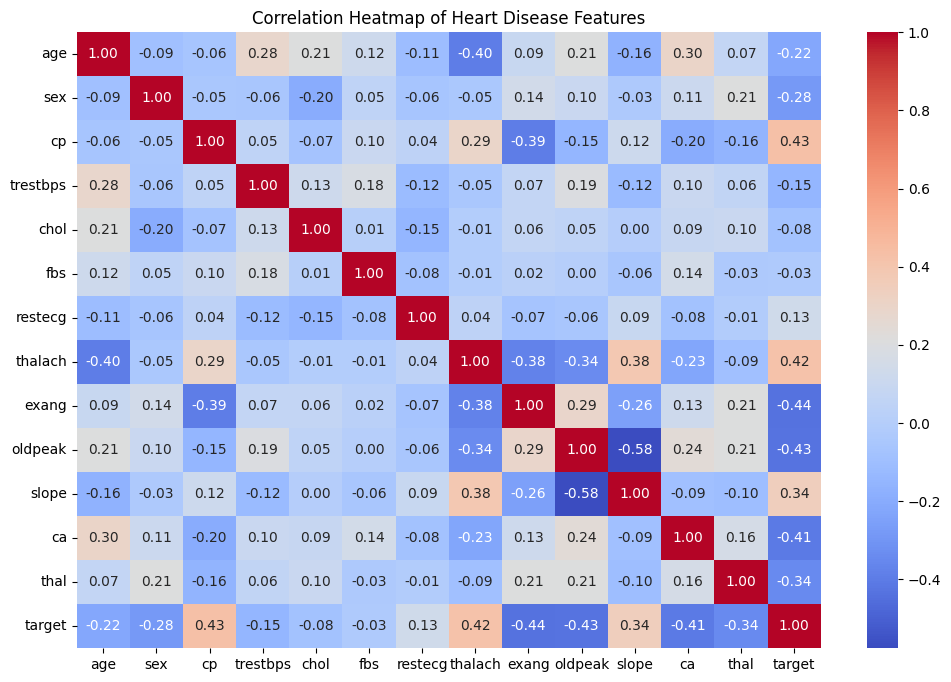

In [33]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap of Heart Disease Features')
plt.show()

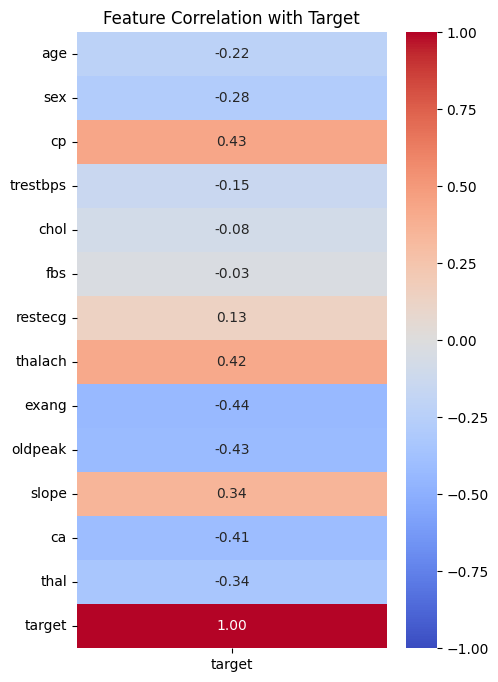

In [34]:
target_corr = df.corr(numeric_only=True)[['target']]

plt.figure(figsize=(5, 8))

sns.heatmap(target_corr, annot=True, cmap='coolwarm', fmt='.2f',
            vmin=-1, vmax=1)

plt.title('Feature Correlation with Target')
plt.show()

### 5.4 Explore the relationship between oldpeak (ST depression) and disease presence.

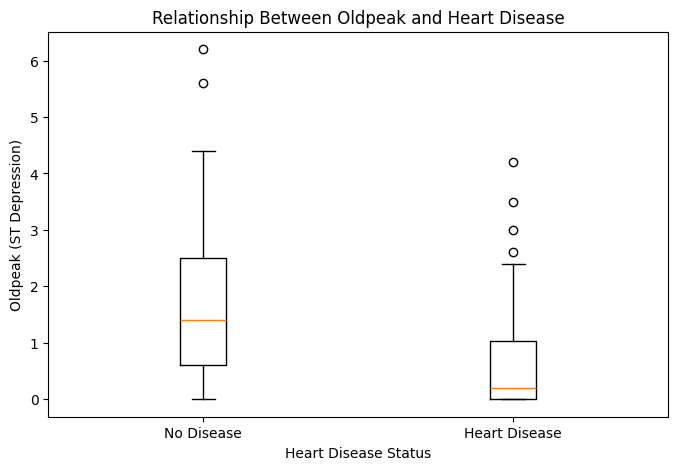

In [35]:
plt.figure(figsize=(8, 5))

plt.boxplot([
    df[df['target'] == 0]['oldpeak'].dropna(),
    df[df['target'] == 1]['oldpeak'].dropna()
], tick_labels=['No Disease', 'Heart Disease'])

plt.xlabel('Heart Disease Status')
plt.ylabel('Oldpeak (ST Depression)')
plt.title('Relationship Between Oldpeak and Heart Disease')

plt.show()

In [36]:
print(df.groupby('target')['oldpeak'].mean())

target
0    1.585507
1    0.586585
Name: oldpeak, dtype: float64


In [37]:
print(df[['oldpeak', 'target']].corr())

          oldpeak    target
oldpeak  1.000000 -0.429146
target  -0.429146  1.000000


## 6. Feature Engineering
### 6.1 One-hot encode categorical-coded columns: cp, restecg, slope, thal.

In [38]:
categorical_cols = ['cp', 'restecg', 'slope', 'thal']

df = pd.get_dummies(df, columns=categorical_cols, dtype=int)

In [39]:
print(df.head())
print(df.columns)
print(df.shape)

   age  sex  trestbps  chol  fbs  thalach  exang  oldpeak  ca  target  ...  \
0   52    1       125   212    0      168      0      1.0   2       0  ...   
1   53    1       140   203    1      155      1      3.1   0       0  ...   
2   70    1       145   174    0      125      1      2.6   0       0  ...   
3   61    1       148   203    0      161      0      0.0   1       0  ...   
4   62    0       138   294    1      106      0      1.9   3       0  ...   

   restecg_0  restecg_1  restecg_2  slope_0  slope_1  slope_2  thal_0  thal_1  \
0          0          1          0        0        0        1       0       0   
1          1          0          0        1        0        0       0       0   
2          0          1          0        1        0        0       0       0   
3          0          1          0        0        0        1       0       0   
4          0          1          0        0        1        0       0       0   

   thal_2  thal_3  
0       0       1  
1   

### 6.2 Scale continuous features (age, trestbps, chol, thalach, oldpeak) with StandardScaler.

In [41]:
continuous_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
scaler = StandardScaler()

df[continuous_cols] = scaler.fit_transform(df[continuous_cols])

In [42]:
print(df[continuous_cols].head())
print(df[continuous_cols].describe())

        age  trestbps      chol   thalach   oldpeak
0 -0.267966 -0.376556 -0.667728  0.806035 -0.037124
1 -0.157260  0.478910 -0.841918  0.237495  1.773958
2  1.724733  0.764066 -1.403197 -1.074521  1.342748
3  0.728383  0.935159 -0.841918  0.499898 -0.899544
4  0.839089  0.364848  0.919336 -1.905464  0.739054
                age      trestbps          chol       thalach       oldpeak
count  3.020000e+02  3.020000e+02  3.020000e+02  3.020000e+02  3.020000e+02
mean  -2.676299e-16 -6.676043e-16 -1.470494e-17 -5.323189e-16 -1.294035e-16
std    1.001660e+00  1.001660e+00  1.001660e+00  1.001660e+00  1.001660e+00
min   -2.814192e+00 -2.144521e+00 -2.332210e+00 -3.436149e+00 -8.995441e-01
25%   -7.107878e-01 -6.617119e-01 -6.870826e-01 -7.137164e-01 -8.995441e-01
50%    1.195033e-01 -9.140084e-02 -1.161266e-01  1.281605e-01 -2.096081e-01
75%    7.283833e-01  4.789102e-01  5.467629e-01  7.185677e-01  4.803280e-01
max    2.499671e+00  3.900776e+00  6.145034e+00  2.292987e+00  4.447460e+00


## 7. Model Building
### 7.1 Separate features (X) and target (y = target).

In [45]:
X = df.drop('target', axis=1)
y = df['target']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (302, 23)
Target shape: (302,)


### 7.2 Split into training and test sets (80/20), stratified by target.

In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape, y_train.shape)
print("Testing set:", X_test.shape, y_test.shape)

Training set: (241, 23) (241,)
Testing set: (61, 23) (61,)


### 7.3 Train a LogisticRegression model on the scaled features. 

In [50]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### 7.4 Generate predictions and predicted probabilities on the test set.

In [51]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

print("Predicted Classes:", y_pred[:10])
print("Predicted Probabilities:", y_prob[:10])

Predicted Classes: [0 0 0 1 1 0 1 0 1 0]
Predicted Probabilities: [0.14663683 0.47903184 0.00960016 0.56904427 0.88741112 0.03686219
 0.84563289 0.07585617 0.97043833 0.48024326]


## 8. Evaluation Tasks
### 8.1 Report accuracy, precision, recall, F1 score, and ROC-AUC.

In [53]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.8360655737704918
Precision: 0.8484848484848485
Recall: 0.8484848484848485
F1 Score: 0.8484848484848485
ROC-AUC: 0.8982683982683983


### 8.2 Plot a confusion matrix and an ROC curve.

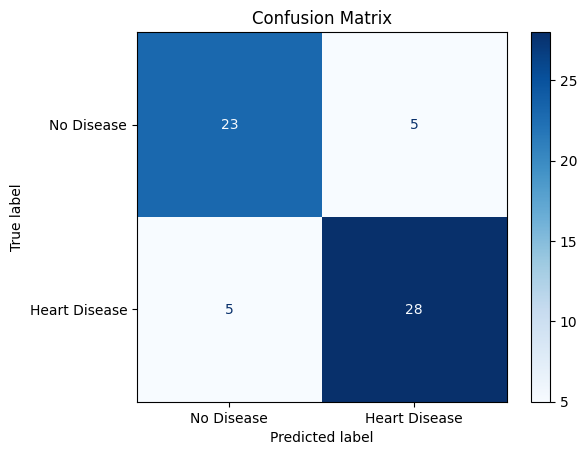

In [56]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Disease', 'Heart Disease']
)

disp.plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

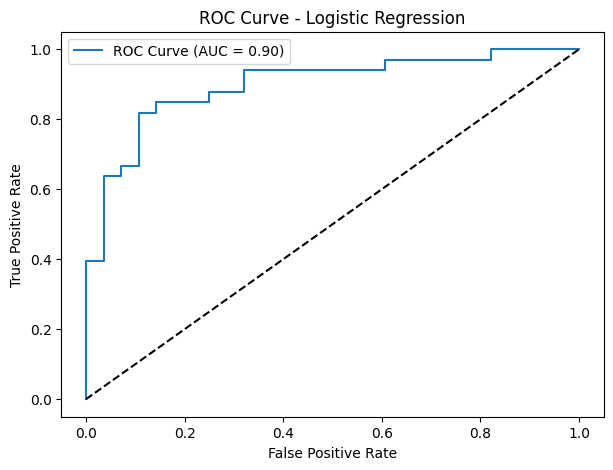

In [58]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend()
plt.show()

### 8.3 Print sorted coefficients to identify the strongest health indicators. 

In [59]:
coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_[0]
})

coefficients['Absolute Value'] = coefficients['Coefficient'].abs()

coefficients = coefficients.sort_values(
    by='Absolute Value', ascending=False
)

print(coefficients)

      Feature  Coefficient  Absolute Value
1         sex    -1.248884        1.248884
9        cp_0    -1.179105        1.179105
6       exang    -0.823493        0.823493
8          ca    -0.758923        0.758923
22     thal_3    -0.736889        0.736889
11       cp_2     0.689041        0.689041
5     thalach     0.681934        0.681934
12       cp_3     0.652479        0.652479
21     thal_2     0.526678        0.526678
20     thal_1     0.380933        0.380933
7     oldpeak    -0.335735        0.335735
17    slope_1    -0.322652        0.322652
18    slope_2     0.303627        0.303627
2    trestbps    -0.286279        0.286279
14  restecg_1     0.281138        0.281138
3        chol    -0.242473        0.242473
13  restecg_0    -0.220021        0.220021
19     thal_0    -0.169590        0.169590
10       cp_1    -0.161283        0.161283
0         age     0.132001        0.132001
15  restecg_2    -0.059985        0.059985
16    slope_0     0.020158        0.020158
4         f

### 8.4 Discuss why recall is especially important for a medical screening use case.
Recall is especially important in medical screening because it measures how effectively a model identifies patients who actually have a disease. High recall minimizes false negatives, reducing the risk of missed diagnoses and ensuring patients receive timely medical attention.

<b>A written summary of the most important health indicators. </b>
The key health indicators associated with heart disease include chest pain type (cp), maximum heart rate (thalach), ST depression (oldpeak), number of major vessels (ca), and thalassemia-related test results (thal). Age, resting blood pressure, and cholesterol may also contribute to heart disease risk. These factors can help predict heart disease presence, although their relative importance depends on the model's actual results.